Importing Dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

In [3]:
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer

In [26]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

Loading and Combining datasets

In [4]:
# Loading fake news
df_fake = pd.read_csv(r"D:\projects\News Fake vs Real Classification\Fake.csv\Fake.csv")
df_fake['label'] = 'FAKE'

# Loading real news
df_real = pd.read_csv(r"D:\projects\News Fake vs Real Classification\True.csv\True.csv")
df_real['label'] = 'REAL'

# Combine datasets
df = pd.concat([df_fake, df_real], ignore_index=True)

# Shuffle data
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

In [5]:
print(df.head())
print(df.info())
print(df.describe())

                                               title  \
0  Ben Stein Calls Out 9th Circuit Court: Committ...   
1  Trump drops Steve Bannon from National Securit...   
2  Puerto Rico expects U.S. to lift Jones Act shi...   
3   OOPS: Trump Just Accidentally Confirmed He Le...   
4  Donald Trump heads for Scotland to reopen a go...   

                                                text       subject  \
0  21st Century Wire says Ben Stein, reputable pr...       US_News   
1  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
3  On Monday, Donald Trump once again embarrassed...          News   
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                  date label  
0    February 13, 2017  FAKE  
1       April 5, 2017   REAL  
2  September 27, 2017   REAL  
3         May 22, 2017  FAKE  
4       June 24, 2016   REAL  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 

In [6]:
# Checking class balance
print(df['label'].value_counts())

label
FAKE    23481
REAL    21417
Name: count, dtype: int64


In [7]:
# Checking for nulls
print(df.isnull().sum())

title      0
text       0
subject    0
date       0
label      0
dtype: int64


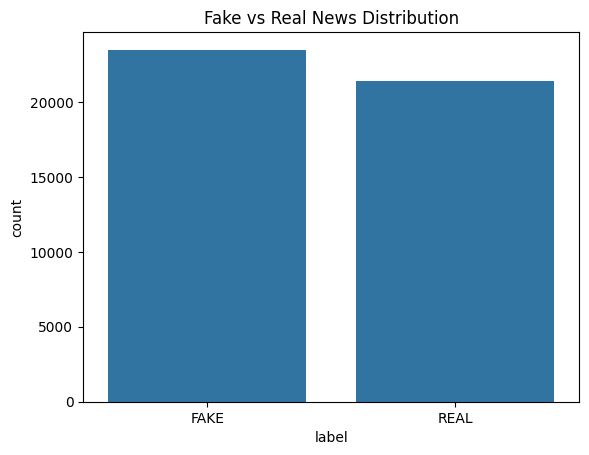

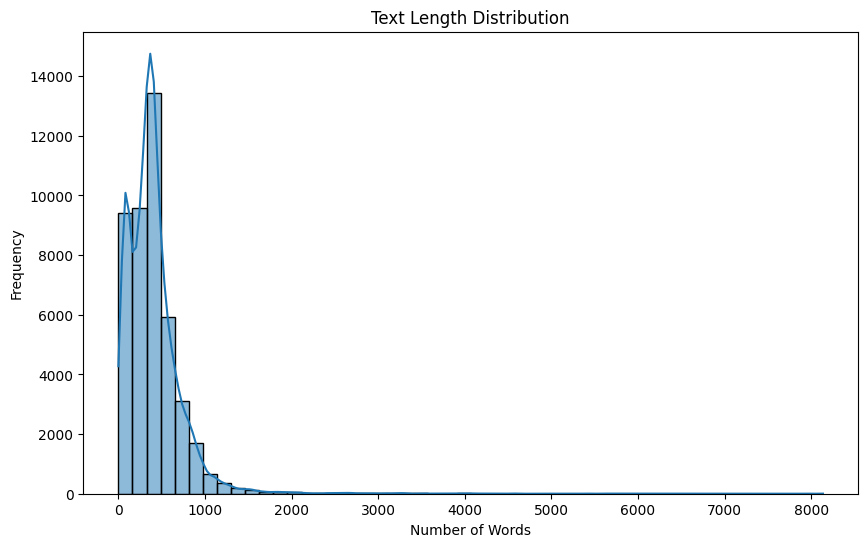

In [8]:
# Plotting class distribution
sns.countplot(x='label', data=df)
plt.title("Fake vs Real News Distribution")
plt.show()

# Adding text length column for analysis
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))

# Plotting text length distribution
plt.figure(figsize=(10,6))
sns.histplot(df['text_length'], bins=50, kde=True)
plt.title("Text Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

- Class imbalance is mild (~52% FAKE, ~48% REAL)
- Most articles are below 1500 words

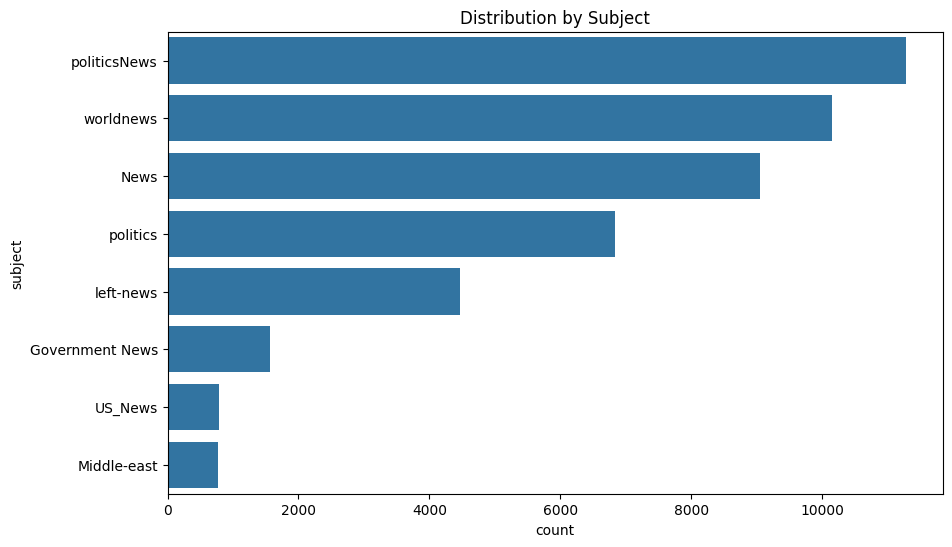

In [9]:
# Subject distribution
plt.figure(figsize=(10,6))
sns.countplot(y='subject', data=df, order=df['subject'].value_counts().index)
plt.title("Distribution by Subject")
plt.show()

Preprocessing
- Dropping irrelevant columns (date)
- Encode label as 0 (REAL) and 1 (FAKE)
- Preparing X and y for modeling
- Train-test split (stratified)

In [10]:
df.head()

,title,text,subject,date,label,text_length
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",FAKE,171
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",REAL,771
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",REAL,304
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",FAKE,183
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",REAL,529


In [11]:
# Dropping unnecessary columns
df_clean = df.drop(['date'], axis=1)

# Combining title and text
df_clean['combined_text'] = df_clean['title'] + '. ' + df_clean['text']

# Using combined_text as X
X = df_clean['combined_text']

# Encoding label: REAL=0, FAKE=1
df_clean['label'] = df_clean['label'].apply(lambda x: 1 if x=='FAKE' else 0)

# targets
y = df_clean['label']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Verifing splits
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Train size: 35918, Test size: 8980
label
1    0.522997
0    0.477003
Name: proportion, dtype: float64
label
1    0.52294
0    0.47706
Name: proportion, dtype: float64


In [12]:
# Vectorize
vectorizer = CountVectorizer(stop_words='english', max_features=10000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Train model
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_vec, y_train)

# Predict and evaluate
y_pred = lr.predict(X_test_vec)
y_prob = lr.predict_proba(X_test_vec)[:,1]

print("Baseline CountVectorizer + Logistic Regression")
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Baseline CountVectorizer + Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4284
           1       1.00      1.00      1.00      4696

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980

ROC-AUC: 0.9995546202580976


Such ~100% accuracy and ROC-AUC on real NLP datasets usually indicates:
Data leakage
- Target labels leaked into features (e.g., if title or text directly contains words like "FAKE" or "REAL")

In [13]:
# Check for label words in combined_text
df_clean[df_clean['combined_text'].str.contains('FAKE|REAL', case=False, na=False)].shape

(13123, 6)

- 13,123 rows (~29%) contain 'FAKE' or 'REAL' in combined_text
- This artificially boosts model accuracy to near-perfect

Option 1. Remove them (Safe and clean)
- Results in smaller but clean dataset
- Model learns true features

Option 2. Replace or mask the leakage words
- Instead of dropping, we can mask 'FAKE' and 'REAL' words with a neutral token like [Label]

In [14]:
# Replace leakage words with neutral token
df_clean['combined_text'] = df_clean['combined_text'].str.replace('FAKE', '[LABEL]', case=False)
df_clean['combined_text'] = df_clean['combined_text'].str.replace('REAL', '[LABEL]', case=False)

# Re-prepare X and y
X = df_clean['combined_text']
y = df_clean['label']

# Re-split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])
print("Train class proportion:\n", y_train.value_counts(normalize=True))
print("Test class proportion:\n", y_test.value_counts(normalize=True))

Train size: 35918 Test size: 8980
Train class proportion:
 label
1    0.522997
0    0.477003
Name: proportion, dtype: float64
Test class proportion:
 label
1    0.52294
0    0.47706
Name: proportion, dtype: float64


In [15]:
# Vectorizing again
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Training baseline Logistic Regression
lr.fit(X_train_vec, y_train)

# Predicting and evaluating
y_pred = lr.predict(X_test_vec)
y_prob = lr.predict_proba(X_test_vec)[:,1]

print("Baseline CountVectorizer + Logistic Regression (after masking)")
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Baseline CountVectorizer + Logistic Regression (after masking)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4284
           1       1.00      1.00      1.00      4696

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980

ROC-AUC: 0.9995425910284613


In [16]:
# How many rows only contain [LABEL] token
only_label_rows = df_clean[df_clean['combined_text'].str.strip() == '[LABEL]']
print("Number of rows with only [LABEL]:", only_label_rows.shape[0])


Number of rows with only [LABEL]: 0


In [17]:
# Check for 'FAKE' or 'REAL' presence after masking (sanity check)
df_clean[df_clean['combined_text'].str.contains('FAKE|REAL', case=False, na=False)].shape


(0, 6)

Model: TF-IDF + SVM

In [18]:
# Vectorize using TF-IDF
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train Linear SVM
svm = LinearSVC()
svm.fit(X_train_tfidf, y_train)

# Predict and evaluate
y_pred_svm = svm.predict(X_test_tfidf)

print("TF-IDF + Linear SVM")
print(classification_report(y_test, y_pred_svm))

TF-IDF + Linear SVM
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4284
           1       1.00      1.00      1.00      4696

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



In [19]:
# Display a few random REAL articles
print("REAL news examples:\n")
print(df_clean[df_clean['label']==1]['combined_text'].sample(3, random_state=42).values)

# Display a few random FAKE articles
print("\nFAKE news examples:\n")
print(df_clean[df_clean['label']==0]['combined_text'].sample(3, random_state=42).values)

REAL news examples:

[" NY Daily News Goes ALL IN On NRA, ‘Thanks’ Them For Orlando (TWEET/IMAGE). The NY Daily News is never shy when it comes to their covers. They re all about calling out badly behaving politicians and political organizations, and they definitely didn t hold back when it came to the horrific act of terror perpetuated against the LGBT community of Orlando, Florida, and the rest of the nation in the wee hours of Sunday morning at Pulse Nightclub. The target of the newspaper s ire this time was the National Rifle Association (NRA).Of course, we all know that this despicable organization is opposed to any and all common sense gun control, and makes a regular practice of whipping gun nuts everywhere up into a frenzy of fear that Democrats and others with a shred of common sense and decency are out to abolish the Second Amendment altogether. They refuse to acknowledge the fact that lax gun laws lead to tragedies like the one that has the world reeling right now, and they 

BERT fine-tuning

In [20]:
from transformers import BertTokenizerFast, BertForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import torch

In [21]:
# Loading BERT tokenizer
tokenizer = BertTokenizerFast.from_pretrained('bert-base-uncased')

# Tokenizer function
def tokenize_function(examples):
    return tokenizer(examples['combined_text'], padding="max_length", truncation=True, max_length=256)

# Converting DataFrame to HuggingFace Dataset
train_dataset = Dataset.from_pandas(pd.concat([X_train, y_train], axis=1).rename(columns={'label': 'labels'}))
test_dataset = Dataset.from_pandas(pd.concat([X_test, y_test], axis=1).rename(columns={'label': 'labels'}))

# Apply tokenization
train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

# Setting format for PyTorch
train_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
test_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])


Map:   0%|          | 0/35918 [00:00<?, ? examples/s]

Map:   0%|          | 0/8980 [00:00<?, ? examples/s]

In [22]:
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
training_args = TrainingArguments(
    output_dir='./results',
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_dir='./logs',
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
)

In [25]:
trainer.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: Currently logged in as: dhinwaji (dhinwaji-iit-bombay) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Step,Training Loss
500,0.026800
1000,0.018100
1500,0.015000
2000,0.008600
2500,0.013800
3000,0.002000
3500,0.010800
4000,0.011000
4500,0.003400
5000,0.005200


TrainOutput(global_step=8980, training_loss=0.008216653753461976, metrics={'train_runtime': 4563.355, 'train_samples_per_second': 15.742, 'train_steps_per_second': 1.968, 'total_flos': 9450422886420480.0, 'train_loss': 0.008216653753461976, 'epoch': 2.0})

In [28]:
# Running predictions on test_dataset
outputs = trainer.predict(test_dataset)

# Converting logits to predicted classes
preds = np.argmax(outputs.predictions, axis=1)

# For ROC-AUC: getting positive class probabilities (assuming label 1 is positive)
probs = outputs.predictions[:,1]

print("Classification Report:\n", classification_report(y_test, preds))
print("ROC-AUC Score:", roc_auc_score(y_test, probs))
print("Confusion Matrix:\n", confusion_matrix(y_test, preds))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      4284
           1       1.00      1.00      1.00      4696

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980

ROC-AUC Score: 1.0
Confusion Matrix:
 [[4284    0]
 [   0 4696]]


In [32]:
train_texts = set(X_train)
test_texts = set(X_test)

overlap = train_texts.intersection(test_texts)
print("Number of overlapping texts:", len(overlap))


Number of overlapping texts: 1822


In [33]:
# Combine text and label for deduplication
df_dedup = df_clean.drop_duplicates(subset=['combined_text'])

print("Data shape after removing duplicate texts:", df_dedup.shape)

# Re-define X and y
X = df_dedup['combined_text']
y = df_dedup['label']

# Re-split on deduplicated data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Final overlap check
train_texts = set(X_train)
test_texts = set(X_test)
overlap = train_texts.intersection(test_texts)
print("Number of overlapping texts after deduplication and re-split:", len(overlap))


Data shape after removing duplicate texts: (39105, 6)
Number of overlapping texts after deduplication and re-split: 0


In [34]:
# Vectorize
vectorizer = CountVectorizer(stop_words='english', max_features=10000)
X_train_cv = vectorizer.fit_transform(X_train)
X_test_cv = vectorizer.transform(X_test)

# Train
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_cv, y_train)

# Predict
preds = lr.predict(X_test_cv)
probs = lr.predict_proba(X_test_cv)[:,1]

# Evaluate
print("Baseline CountVectorizer + Logistic Regression")
print(classification_report(y_test, preds))
print("ROC-AUC:", roc_auc_score(y_test, probs))

Baseline CountVectorizer + Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4239
           1       0.99      0.99      0.99      3582

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821

ROC-AUC: 0.9993407576795144


In [35]:
from sklearn.calibration import CalibratedClassifierCV

# Vectorize
tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train
svm = LinearSVC(max_iter=10000)
svm_calibrated = CalibratedClassifierCV(svm)
svm_calibrated.fit(X_train_tfidf, y_train)

# Predict
preds = svm_calibrated.predict(X_test_tfidf)
probs = svm_calibrated.predict_proba(X_test_tfidf)[:,1]

# Evaluate
print("TF-IDF + Linear SVM")
print(classification_report(y_test, preds))
print("ROC-AUC:", roc_auc_score(y_test, probs))

TF-IDF + Linear SVM
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4239
           1       0.99      0.99      0.99      3582

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821

ROC-AUC: 0.9997100914390832


In [40]:
output_dir = "./bert_fake_news_model"

model.save_pretrained(output_dir)
tokenizer.save_pretrained(output_dir)

print(f"Model and tokenizer saved to {output_dir}")

Model and tokenizer saved to ./bert_fake_news_model


In [38]:
from lime.lime_text import LimeTextExplainer
from transformers import BertTokenizerFast, BertForSequenceClassification

In [ ]:
# Load tokenizer and trained model
model_dir = "./bert_fake_news_model"
tokenizer = BertTokenizerFast.from_pretrained(model_dir)
model = BertForSequenceClassification.from_pretrained(model_dir)
model.eval()

# Defining class names for LIME
class_names = ['FAKE', 'REAL']

# Defining a prediction function that LIME expects
def predict_prob(texts):
    inputs = tokenizer(texts, padding=True, truncation=True, max_length=256, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=1).numpy()
    return probs

# Creating LIME explainer
explainer = LimeTextExplainer(class_names=class_names)

# Choosing a test sample to explain
i = 10  # example index
sample_text = X_test.iloc[i]

# Explain instance
exp = explainer.explain_instance(sample_text, predict_prob, num_features=15)

# Visualize explanation
exp.show_in_notebook(text=sample_text)

# Saving explanation as HTML
exp.save_to_file('lime_explanation_sample10.html')